# 집값 예측 컴피티션: 회귀 모델 개선 기록(38,019에서 18,150까지)

**AI 데이터 인텔리전스 › 필수 머신러닝 › 집값 예측 컴피티션** · 정리 노트북

**[Modulabs-DI2기] House Price Prediction** · 지표: RMSE(달러) · 리더보드: test 292채 **전체**로 채점

| 항목 | 값 |
|---|---|
| 출발점 (템플릿 그대로) | 예측 붕괴: 평균 8.9만 달러, 음수 28개 |
| 1차 제출 (버그 수정 후 LinearRegression) | 38,019 |
| **최종 제출** | **18,150 (17차)** |
| 오차 감소 | 1차 대비 약 52% |

이 노트북은 대회 과정 전체를 **처음부터 끝까지 실행하면 최종 제출 파일이 그대로 재현되도록** 정리한 것이다.
각 섹션은 **무엇을 했나 → 왜 했나 → 결과는 어땠나** 순서로 읽으면 된다.

### 최종 모델 한눈에 보기
```
train 1,168채
  │ ① 전처리: 결측을 train의 중앙값·최빈값으로 채움 → 원-핫 인코딩 (Id 제외)
  │ ② 이상치 제거: 아주 큰데 싼 집 2채 + 모델이 설명 못 하는 집(잔차 2.5σ↑)
  │ ③ 집값을 log로 바꿔 학습
  ▼
  │  Ridge / Lasso / GBR / GBR_d4 / XGB
  │ ④ 가중 평균(블렌드): Ridge 25.0%, Lasso 25.0%, GBR 16.7%, GBR_d4 16.7%, XGB 16.7%
  │ ⑤ 달러로 복원 → 늘이기 보정 p × (p / 163,000) ^ 0.04
  ▼
test 292채 예측 → submission_final.csv
```

### 목차
1. 데이터 불러오기 · 2. 데이터 탐색(EDA) · 3. 전처리 · 4. 검증 설계 · 5. 이상치 처리
6. 단일 모델 비교 · 7. 앙상블 · 8. 늘이기 보정 · 9. 최종 모델 학습과 제출 파일
10. 제출 이력과 검증 vs 리더보드 · 11. 학습노트

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")                 # pandas 버전 안내 경고 숨김(결과에 영향 없음)

from sklearn import set_config
set_config(display="text")                         # 한글 윈도우에서 모델 HTML 표시 에러 방지

plt.rcParams["font.family"] = "Malgun Gothic"      # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False

## 1. 데이터 불러오기

- `train.csv`: 정답(SalePrice)이 있는 1,168채 → 모델이 공부하는 데이터
- `test.csv`: 정답이 없는 292채 → 예측해서 제출하는 대상
- 원본 Kaggle 데이터는 이 대회 test의 정답을 포함하므로 **사용하지 않는다**(정답 누수).

In [2]:
import os
DATA = "./" if os.path.exists("./train.csv") else "../"   # 데이터 위치: 같은 폴더 또는 상위 폴더
train_raw = pd.read_csv(DATA + "train.csv")
test_raw = pd.read_csv(DATA + "test.csv")
print("train:", train_raw.shape, "/ test:", test_raw.shape)

train: (1168, 81) / test: (292, 80)


## 2. 데이터 탐색 (EDA)

질문 하나에 그래프 하나. 그래프 제목에 **읽는 법**을 적었다.

In [3]:
na = train_raw.isnull().sum()
na = na[na > 0].sort_values(ascending=False)
print(f"결측이 있는 컬럼 {len(na)}개 (train 1,168채 기준)")
print(na)

결측이 있는 컬럼 19개 (train 1,168채 기준)
PoolQC          1162
MiscFeature     1120
Alley           1098
Fence            941
MasVnrType       694
FireplaceQu      545
LotFrontage      218
GarageType        69
GarageYrBlt       69
GarageFinish      69
GarageQual        69
GarageCond        69
BsmtExposure      24
BsmtFinType2      24
BsmtQual          23
BsmtCond          23
BsmtFinType1      23
MasVnrArea         8
Electrical         1
dtype: int64


**해석** — 결측(NaN)이 모두 '모름'은 아니다.
- `PoolQC`(1,162)·`MiscFeature`·`Alley`·`Fence`·`FireplaceQu`: 대부분 **그 시설이 없음**을 뜻한다.
- Garage 관련 5개가 모두 69 → 같은 69채가 '차고 없음'이다(구조적 결측).
- `LotFrontage`(218)는 진짜 모르는 값이다.

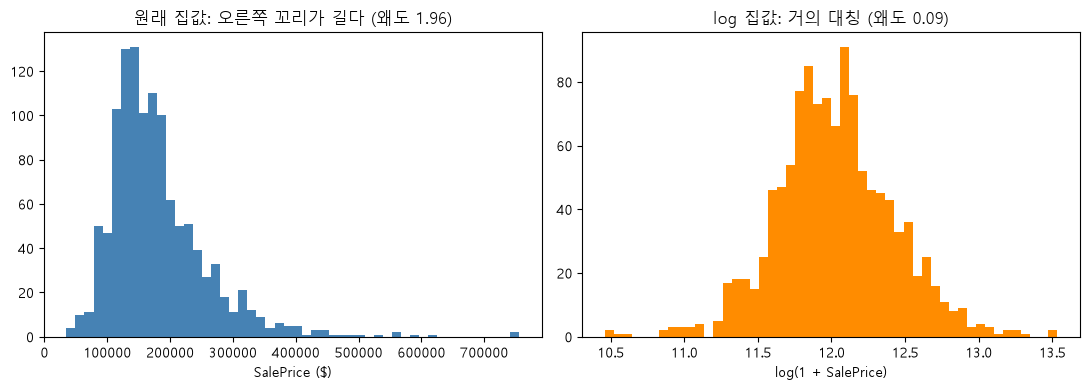

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train_raw["SalePrice"], bins=50, color="steelblue")
axes[0].set_title(f"원래 집값: 오른쪽 꼬리가 길다 (왜도 {train_raw['SalePrice'].skew():.2f})")
axes[0].set_xlabel("SalePrice ($)")
axes[1].hist(np.log1p(train_raw["SalePrice"]), bins=50, color="darkorange")
axes[1].set_title(f"log 집값: 거의 대칭 (왜도 {np.log1p(train_raw['SalePrice']).skew():.2f})")
axes[1].set_xlabel("log(1 + SalePrice)")
plt.tight_layout(); plt.show()

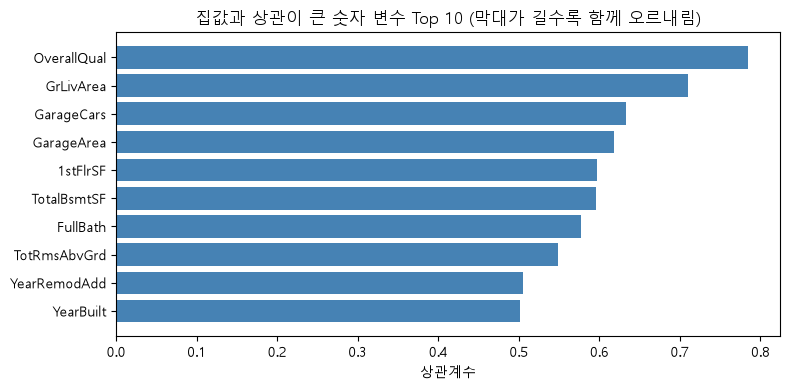

In [5]:
corr = train_raw.select_dtypes("number").drop(columns="Id").corr()["SalePrice"]
top10 = corr.drop("SalePrice").sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4))
plt.barh(top10.index[::-1], top10.values[::-1], color="steelblue")
plt.title("집값과 상관이 큰 숫자 변수 Top 10 (막대가 길수록 함께 오르내림)")
plt.xlabel("상관계수"); plt.tight_layout(); plt.show()

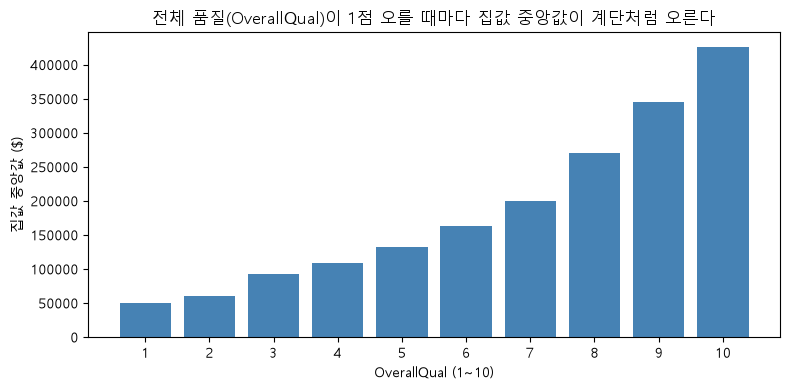

In [6]:
qual = train_raw.groupby("OverallQual")["SalePrice"].median()
plt.figure(figsize=(8, 4))
plt.bar(qual.index, qual.values, color="steelblue")
plt.title("전체 품질(OverallQual)이 1점 오를 때마다 집값 중앙값이 계단처럼 오른다")
plt.xlabel("OverallQual (1~10)"); plt.ylabel("집값 중앙값 ($)"); plt.xticks(qual.index)
plt.tight_layout(); plt.show()

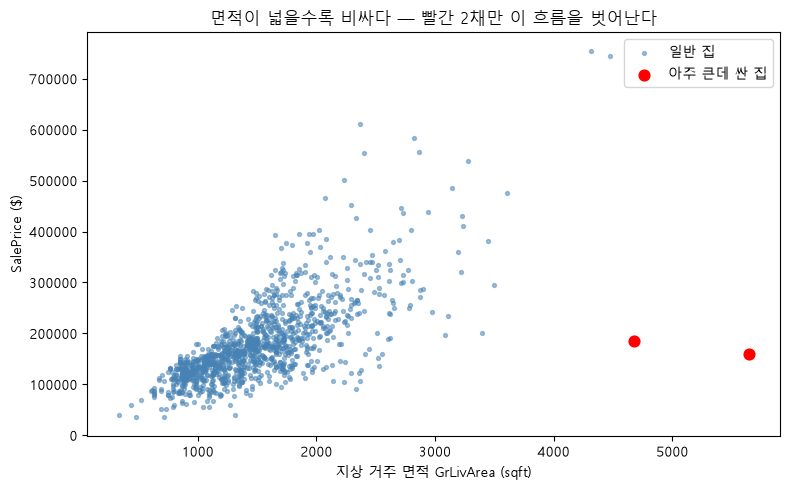

       Id  GrLivArea  OverallQual SaleCondition  SalePrice
64   1299       5642           10       Partial     160000
373   524       4676           10       Partial     184750


In [7]:
big_cheap = (train_raw["GrLivArea"] > 4000) & (train_raw["SalePrice"] < 300000)
plt.figure(figsize=(8, 5))
plt.scatter(train_raw.loc[~big_cheap, "GrLivArea"], train_raw.loc[~big_cheap, "SalePrice"], s=8, alpha=0.5, color="steelblue", label="일반 집")
plt.scatter(train_raw.loc[big_cheap, "GrLivArea"], train_raw.loc[big_cheap, "SalePrice"], s=60, color="red", label="아주 큰데 싼 집")
plt.title("면적이 넓을수록 비싸다 — 빨간 2채만 이 흐름을 벗어난다")
plt.xlabel("지상 거주 면적 GrLivArea (sqft)"); plt.ylabel("SalePrice ($)"); plt.legend()
plt.tight_layout(); plt.show()
print(train_raw.loc[big_cheap, ["Id", "GrLivArea", "OverallQual", "SaleCondition", "SalePrice"]])

#### EDA 정리
1. **집값 분포**: 비싼 집 쪽으로 꼬리가 길다(왜도 1.96). log를 씌우면 거의 대칭(0.09)이 된다.
   → 모델이 소수의 비싼 집에 휘둘리지 않도록 **log(집값)으로 학습**하고, 예측 후 달러로 되돌린다.
2. **주요 변수**: 전체 품질(0.79)과 거실 면적(0.71)이 가장 강하다. "얼마나 좋은 집이고, 얼마나 큰가"가 핵심이다.
3. **품질과 가격**: 품질 1점마다 중앙값이 꾸준히 오른다(5점 13만 → 8점 27만 → 10점 43만 달러). log 공간에서 거의 직선 관계 → **선형 모델이 강할 것**이라는 예상의 근거가 된다.
4. **이상치**: 4,000sqft가 넘는데 30만 달러 미만인 2채(Id 1299, 524)는 품질 10점인데 '공사 중 판매(Partial)'라 정상 시세가 아니다 → 학습에서 제외한다.
   크고 비싼 2채(75만 달러 근처)는 흐름을 따르므로 남긴다.

## 3. 전처리

### 3-1. 템플릿의 버그: test를 '자기 자신' 기준으로 처리했다
템플릿은 test 결측을 **test의** 최빈값으로 채우고, test만 따로 `get_dummies(drop_first=True)` 했다.
그 결과 1차 제출 전 예측이 평균 8.9만 달러, 음수 28개로 붕괴했다. 아래 셀이 원인을 보여 준다.

In [8]:
print("PoolQC 최빈값 — train:", train_raw["PoolQC"].mode()[0], "/ test:", test_raw["PoolQC"].mode()[0])
print("train에서 PoolQC='Gd'인 집:", (train_raw["PoolQC"] == "Gd").sum(), "채")
print()
print("RoofMatl 종류 — train:", sorted(train_raw["RoofMatl"].unique()))
print("RoofMatl 종류 — test :", sorted(test_raw["RoofMatl"].unique()))

PoolQC 최빈값 — train: Ex / test: Gd
train에서 PoolQC='Gd'인 집: 2 채

RoofMatl 종류 — train: ['ClyTile', 'CompShg', 'Metal', 'Roll', 'Tar&Grv', 'WdShake', 'WdShngl']
RoofMatl 종류 — test : ['CompShg', 'Membran', 'Tar&Grv', 'WdShake', 'WdShngl']


- **PoolQC**: test는 1채만 실제 값('Gd')이 있고 291채가 결측이다. 결측 291채가 test 최빈값 'Gd'로 채워져 **292채 전부 'Gd'**가 됐다. 'Gd'인 집은 train 전체에 2채, 학습용 80%에는 **단 1채**뿐이었고, 모델은 그 1채로 −64만 달러짜리 계수를 배웠다 → test 전체가 크게 깎였다.
- **RoofMatl**: test에는 희귀 지붕재가 없어 알파벳 첫 범주가 `CompShg`가 된다. test만 따로 `drop_first`를 하면 대다수 집의 `RoofMatl_CompShg` 컬럼이 사라진다.

**원칙**: 채우는 값은 **train에서만** 구하고(Ch4 데이터 누수), train과 test에 **같은 함수**를 적용한다.

In [9]:
def preprocess(df):
    df = df.copy()
    df = df.fillna(train_raw.median(numeric_only=True))          # 숫자 빈칸 → train 중앙값
    for col in df.select_dtypes(include="object"):
        df[col] = df[col].fillna(train_raw[col].mode()[0])       # 글자 빈칸 → train 최빈값
    return df

train_df = pd.get_dummies(preprocess(train_raw), drop_first=True)   # 글자 → 0/1 컬럼
X = train_df.drop(columns=["SalePrice"])
y = train_df["SalePrice"]

test_X = pd.get_dummies(preprocess(test_raw))                        # test는 drop_first 없이
test_X = test_X.reindex(columns=X.columns, fill_value=0)             # train 컬럼에 정확히 맞춤

print("X:", X.shape, "/ test_X:", test_X.shape, "/ 남은 결측:", X.isnull().sum().sum(), test_X.isnull().sum().sum())

X: (1168, 242) / test_X: (292, 242) / 남은 결측: 0 0


### 3-2. 시도했다가 버린 전처리
결측을 'None' 범주로 채우기, 품질 등급을 숫자로(Ex=5…), 파생변수(총면적·집 나이·욕실 합계·품질×면적)를 넣는 '변수 다듬기'를 시도했다.
CV에서는 0.7% 좋아졌지만 **리더보드에서는 +631 나빠졌다**(8차 원인분석 제출). 새 변수들이 고급 주택 가격을 과하게 끌어올렸다.
→ 단순한 전처리를 유지했다. **CV가 좋아도 리더보드가 최종 판정**이라는 교훈.

## 4. 검증 설계

| 검증 방법 | 데이터 | 쓰임 |
|---|---|---|
| 홀드아웃 | train 80% 학습 / 20%(234채) 검증 | 템플릿 방식, 빠른 확인 |
| **5-fold 교차검증(CV)** | 1,168채를 5번 나눠 모두 한 번씩 검증 | 후보 비교. 234채보다 덜 흔들린다 |
| 리더보드 | test 292채 **전체** (숨겨진 Private 없음) | **최종 판정** |

**CV에서 누수를 막는 방법 (Ch4)** — 각 fold마다 **fold의 학습 데이터만으로** 결측 채움 값(중앙값·최빈값)과 원-핫 컬럼 목록을 정하고,
검증 fold는 그 기준에 맞춰 변환한다(test를 처리하는 방식과 같다). 이상치 제거·모델 학습도 fold 안에서 다시 한다.

**채점 기준** — 채점에서 뺄 집을 **가격(정답)을 보지 않고** 정한다. test의 최대 면적은 3,627sqft라서, 4,000sqft를 넘는 집은 test에 없다.
그래서 검증 fold에서 **면적 4,000sqft 이하인 집 전부**(= test와 같은 범위)를 채점한 값을 **기본 지표**로 쓰고, 모든 집을 채점한 값은 **참고 지표**로 함께 적는다.

> **검증 범위 명시** — 본 검증의 주요 CV 지표는 최종 예측 대상(test)의 면적 범위를 고려하여 4,000sqft 이하 주택에서 산출한 **조건부 성능**이며, 전체 주택에 대한 CV 결과는 별도로 제시하였다. 이 범위는 test의 **면적(피처) 분포**를 확인하고 정했다. 정답 누수는 아니지만 평가 대상의 특성을 검증 설계에 반영한 것이다. 두 지표는 평가 대상이 다르므로, 한쪽이 낮다고 다른 쪽이 틀렸다는 뜻은 아니다.

> 처음에는 '아주 큰데 **싼** 집'(가격 조건 포함)을 채점에서 뺐다. 이는 정답을 보고 평가 대상을 고르는 것이라 바로잡았다.

In [10]:
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from xgboost import XGBRegressor



Z_CUT = 2.5   # 잔차 기반 이상치 기준(표준편차 배수)

def remove_outliers(X, y):
    """① 아주 큰데 싼 집 제거 → ② 잔차 2.5σ 넘는 집 제거. (X, log_y, 제거 수) 반환"""
    X = X.drop(columns="Id")
    keep = ~((X["GrLivArea"] > 4000) & (y < 300000))
    X, log_y = X[keep], np.log1p(y[keep])
    check = make_pipeline(RobustScaler(), Ridge(alpha=10)).fit(X, log_y)   # 점검용 모델
    resid = log_y - check.predict(X)                                       # 예측과 실제 차이(잔차)
    z = (resid - resid.mean()) / resid.std()                               # 표준편차 몇 배인지
    keep2 = z.abs() < Z_CUT
    return X[keep2], log_y[keep2], int((~keep).sum() + (~keep2).sum())

## 5. 이상치 처리

1. **아주 큰데 싼 집 2채** — EDA ④의 근거.
2. **잔차 기반 제거** — Ridge로 한 번 맞춰 보고, 예측과 실제의 차이(잔차)가 평균에서 **2.5 표준편차(σ)** 넘게 벗어난 집을 학습에서 뺀다.
   '모델이 도저히 설명하지 못하는 거래'(급매, 가족 간 거래, 기록 오류 등)를 배우지 않게 하려는 것이다.

학습에서 제외: 29채 (1,168채 중 2.5%)
제외된 집의 판매 조건: {'Normal': 10, 'Abnorml': 9, 'Partial': 7, 'Alloca': 2, 'Family': 1}
전체 train의 판매 조건: {'Normal': 959, 'Partial': 99, 'Abnorml': 78, 'Family': 17, 'Alloca': 11, 'AdjLand': 4}


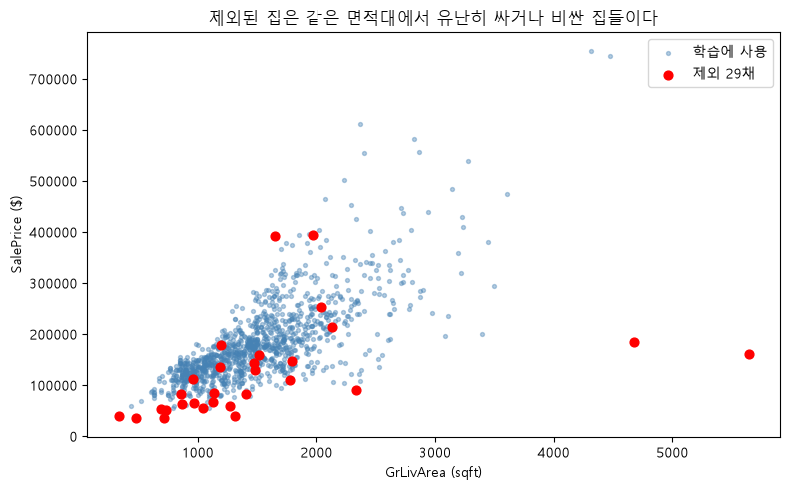

In [11]:
X_clean, logy_clean, n_removed = remove_outliers(X, y)
removed_ids = sorted(set(X["Id"]) - set(X.loc[X_clean.index, "Id"]))
removed = train_raw[train_raw["Id"].isin(removed_ids)]
print(f"학습에서 제외: {n_removed}채 (1,168채 중 {n_removed/len(X)*100:.1f}%)")
print("제외된 집의 판매 조건:", removed["SaleCondition"].value_counts().to_dict())
print("전체 train의 판매 조건:", train_raw["SaleCondition"].value_counts().to_dict())

plt.figure(figsize=(8, 5))
keep_mask = ~train_raw["Id"].isin(removed_ids)
plt.scatter(train_raw.loc[keep_mask, "GrLivArea"], train_raw.loc[keep_mask, "SalePrice"], s=8, alpha=0.4, color="steelblue", label="학습에 사용")
plt.scatter(removed["GrLivArea"], removed["SalePrice"], s=40, color="red", label=f"제외 {n_removed}채")
plt.title("제외된 집은 같은 면적대에서 유난히 싸거나 비싼 집들이다")
plt.xlabel("GrLivArea (sqft)"); plt.ylabel("SalePrice ($)"); plt.legend()
plt.tight_layout(); plt.show()

**근거 확인** — 제외된 29채 중 '비정상 거래(Abnorml)'는 9채(약 31%)로, 전체 train의 비율(약 7%)보다 **상대적으로 높다**(위 출력 참고).
잔차 기준이 정상 시세에서 벗어난 거래를 **더 많이** 골라냈다는 근거이지만, 제외된 집이 모두 비정상 거래인 것은 아니다(Normal도 10채).

**결과 (리더보드)** — 기준값을 바꿔 가며 같은 모델로 제출했다.

| 잔차 기준 | 제외(2채 포함 안 함) | 리더보드 |
|---|---|---|
| 제거 안 함 (5차) | 0 | 19,412 |
| 3.5σ | 10채 | 19,079 |
| 3σ | 15채 | 18,968 |
| **2.5σ** | **27채** | **18,895** |

노트북 밖에서 돌린 반복 CV(비정상 2채 제외 기준)도 같은 방향(2.5σ가 가장 좋음, 2σ는 다시 나빠짐)이었다. **많이 빼되 지나치지 않게**가 핵심이다.

## 6. 단일 모델 비교 (5-fold CV)

같은 전처리·같은 이상치 처리·같은 fold에서 모델만 바꿔 비교한다. 아래 셀은 몇 분 걸린다.

In [12]:
# 비교할 모델들 (모두 log 집값을 학습)
MODELS = {
    "Ridge": lambda: make_pipeline(RobustScaler(), Ridge(alpha=3)),   # 선형 + L2 규제: 계수를 전체적으로 작게
    "Lasso": lambda: make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),   # 선형 + L1 규제: 쓸모없는 컬럼 계수를 0으로
    "GBR": lambda: GradientBoostingRegressor(n_estimators=1500, learning_rate=0.03, max_depth=3,
                                      subsample=0.8, max_features="sqrt", random_state=42),   # 트리 부스팅(얕은 트리 1,500개)
    "GBR_d4": lambda: GradientBoostingRegressor(n_estimators=2000, learning_rate=0.02, max_depth=4, subsample=0.8,
                                      max_features="sqrt", min_samples_leaf=5, random_state=42),   # 트리 부스팅(조금 깊은 트리 2,000개)
    "XGB": lambda: XGBRegressor(n_estimators=2000, learning_rate=0.02, max_depth=3, subsample=0.8,
                         colsample_bytree=0.3, min_child_weight=2, random_state=42),   # XGBoost(컬럼 30%만 보며 학습)
}

test 최대 면적: 3627 / train에서 4,000 초과: 4 채


        test 범위 집 (기본)  전체 집 (참고)
Lasso          20338.0    56196.0
Ridge          20693.0    53847.0
GBR_d4         20740.0    28313.0
XGB            21181.0    28669.0
GBR            21361.0    28606.0


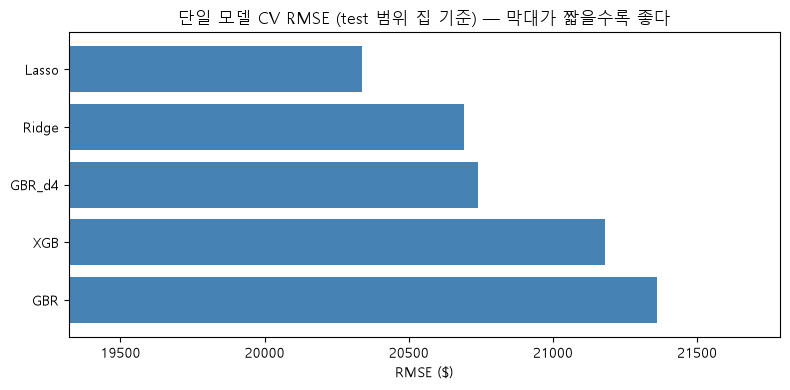

In [13]:
TEST_MAX_AREA = 4000   # test의 최대 GrLivArea는 3,627 → 4,000 초과 집은 test에 없다
print("test 최대 면적:", test_raw["GrLivArea"].max(), "/ train에서 4,000 초과:", (train_raw["GrLivArea"] > TEST_MAX_AREA).sum(), "채")

folds = list(KFold(n_splits=5, shuffle=True, random_state=0).split(train_raw))
oof = {name: [] for name in MODELS}     # fold별 log 예측 저장
y_true, mask = [], []

for tr_idx, va_idx in folds:
    raw_tr, raw_va = train_raw.iloc[tr_idx], train_raw.iloc[va_idx]

    # ① fold의 학습 데이터만으로 전처리 기준을 정한다 (검증 fold 정보 차단)
    fold_median = raw_tr.median(numeric_only=True)
    fold_mode = {col: raw_tr[col].mode()[0] for col in raw_tr.select_dtypes(include="object")}
    def prep_fold(df):
        df = df.fillna(fold_median)
        for col, value in fold_mode.items():
            df[col] = df[col].fillna(value)
        return df
    X_tr = pd.get_dummies(prep_fold(raw_tr), drop_first=True).drop(columns="SalePrice")
    X_va = pd.get_dummies(prep_fold(raw_va)).reindex(columns=X_tr.columns, fill_value=0)   # test와 같은 방식
    y_tr, y_va = raw_tr["SalePrice"], raw_va["SalePrice"]

    # ② 이상치 제거·학습도 fold 안에서
    X_fit, logy_fit, _ = remove_outliers(X_tr, y_tr)
    for name, make in MODELS.items():
        oof[name].append(make().fit(X_fit, logy_fit).predict(X_va.drop(columns="Id")))
    y_true.append(y_va.values)
    mask.append((raw_va["GrLivArea"] <= TEST_MAX_AREA).values)   # 가격은 보지 않고 면적만으로: test 범위 안의 집

def cv_rmse(log_preds, stretch=0.0, exclude=False):
    """fold별 log 예측 → 달러 복원(+보정) → fold RMSE 평균. exclude=True면 test 범위(면적 ≤ 4,000) 집만 채점"""
    scores = []
    for p, t, m in zip(log_preds, y_true, mask):
        price = np.expm1(p)
        price = price * (price / 163000) ** stretch
        err = (price - t)[m] if exclude else (price - t)
        scores.append(np.sqrt(np.mean(err ** 2)))
    return np.mean(scores)

def both(log_preds, stretch=0.0):
    return {"test 범위 집 (기본)": cv_rmse(log_preds, stretch, exclude=True), "전체 집 (참고)": cv_rmse(log_preds, stretch)}

single = pd.DataFrame({name: both(oof[name]) for name in MODELS}).T.sort_values("test 범위 집 (기본)")
print(single.round(0))

plt.figure(figsize=(8, 4))
plt.barh(single.index[::-1], single["test 범위 집 (기본)"][::-1], color="steelblue")
plt.xlim(single["test 범위 집 (기본)"].min() * 0.95, single["test 범위 집 (기본)"].max() * 1.02)
plt.title("단일 모델 CV RMSE (test 범위 집 기준) — 막대가 짧을수록 좋다")
plt.xlabel("RMSE ($)"); plt.tight_layout(); plt.show()

**해석 1 — 두 지표가 왜 이렇게 다른가?** 전체 집(참고)에서 선형 모델 점수가 크게 나쁜 것은 4,000sqft가 넘는 **4채** 때문이다.
선형 모델은 면적에 비례해 값을 키우므로, 학습 범위를 벗어난 초대형 집을 크게 과대·과소 예측한다(외삽). 트리는 학습 범위 안의 값만 내놓아 덜 흔들린다.
test에는 이런 집이 없으므로 기본 지표(test 범위)가 리더보드를 더 잘 대변한다. **"검증 데이터가 test와 같은 분포인가"를 먼저 확인해야 한다**는 교훈이다.

**해석 2** — test 범위 기준으로는 Kaggle 단골인 부스팅(트리) 모델보다 **규제 선형 모델(Ridge·Lasso)이 더 강하다.**
- 데이터가 1,168채로 작아 트리가 세밀한 규칙을 배우기 어렵다.
- EDA ③처럼 log(집값)과 품질·면적의 관계가 거의 직선이다.
- 규제(Ridge·Lasso)는 원-핫 컬럼 200여 개 중 드문 범주에 극단적 계수가 붙는 것을 막는다(1차의 −64만 달러 수영장 계수 같은 과적합 방지).

**추가로 시험한 모델 (노트북 밖 반복 CV: 5-fold × 2회, 비정상 2채 제외 기준)** — 실행 시간을 줄이려고 결과만 기록한다. 위 표와 채점 기준이 달라 숫자를 직접 비교하지 않는다.

| 모델 | CV RMSE | 판정 |
|---|---|---|
| ElasticNet (L1·L2 혼합 규제) | 20,303 | Lasso와 거의 같음 |
| LightGBM | 22,412 | 단일 모델 중 하위 |
| CatBoost | 22,756 | 단일 모델 중 최하위 |
| SVR · KernelRidge | 22,900 이상 | 크게 나쁨 |

같은 실험에서 블렌드에 섞어도 최종 블렌드(19,454) 대비 개선이 0.3% 이하였고, 10번 중 절반만 좋아져서 **채택하지 않았다.**

## 7. 앙상블 (블렌드)

여러 모델의 log 예측을 **가중 평균**한다. 선형 모델과 트리 모델은 틀리는 방식이 달라서 평균하면 오차가 서로 상쇄된다.

In [14]:
# 최종 블렌드 가중치: 선형 50% + 트리 50%
WEIGHTS = {"Ridge": 0.25, "Lasso": 0.25, "GBR": 0.16666666666666666, "GBR_d4": 0.16666666666666666, "XGB": 0.16666666666666666}
STRETCH = 0.04

def blend_log(preds):
    """모델별 fold 예측(log) → 가중 평균(log)"""
    return [sum(w * preds[name][i] for name, w in WEIGHTS.items()) for i in range(len(folds))]

In [15]:
best_single = single.index[0]
compare = pd.DataFrame({
    f"최고 단일 모델 ({best_single})": both(oof[best_single]),
    "블렌드": both(blend_log(oof)),
    f"블렌드 + 늘이기 보정 {STRETCH}": both(blend_log(oof), STRETCH),
}).T
print(compare.round(0))

                   test 범위 집 (기본)  전체 집 (참고)
최고 단일 모델 (Lasso)          20338.0    56196.0
블렌드                       19627.0    36093.0
블렌드 + 늘이기 보정 0.04         19537.0    37747.0


**블렌드 구성의 변천 (리더보드)**

| 차수 | 구성 | 리더보드 |
|---|---|---|
| 3차 | Ridge + GBR (1/2씩) | 20,015 |
| 5차 | Ridge + Lasso + GBR (1/3씩) | 19,412 |
| 7차 | 5차에서 GBR → XGB | 19,543 (나빠짐) |
| 12차 | 2.5σ 데이터, Ridge(3)·Lasso 70% + GBR·XGB 30% | 18,805 |
| 17차 | 선형 50% + 트리 50%(GBR·깊이4 GBR·XGB), 보정 0.04 | 18,150 |

## 8. 늘이기 보정

규제가 걸린 모델은 예측을 **평균 쪽으로 끌어당긴다** → 비싼 집은 조금 싸게, 싼 집은 조금 비싸게 예측한다.
달러 RMSE에서는 비싼 집의 오차가 크게 벌점을 받으므로 이게 손해다. 그래서 예측을 중앙값(163,000달러) 기준으로 살짝 편다.

$$\text{보정 예측} = p \times \left(\frac{p}{163{,}000}\right)^{a}$$

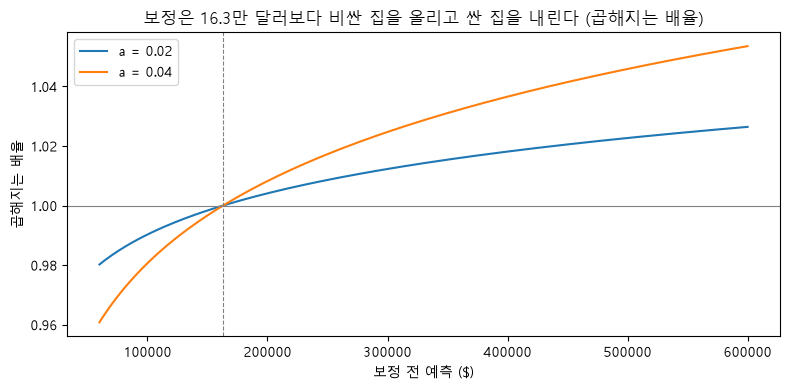

      test 범위 집 (기본)  전체 집 (참고)
0.00         19627.0    36093.0
0.01         19535.0    36433.0
0.02         19488.0    36821.0
0.03         19488.0    37259.0
0.04         19537.0    37747.0
0.05         19635.0    38288.0


In [16]:
prices = np.linspace(60000, 600000, 200)
plt.figure(figsize=(8, 4))
for a in (0.02, 0.04):
    plt.plot(prices, (prices / 163000) ** a, label=f"a = {a}")
plt.axhline(1, color="gray", lw=0.8); plt.axvline(163000, color="gray", lw=0.8, ls="--")
plt.title("보정은 16.3만 달러보다 비싼 집을 올리고 싼 집을 내린다 (곱해지는 배율)")
plt.xlabel("보정 전 예측 ($)"); plt.ylabel("곱해지는 배율"); plt.legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({a: both(blend_log(oof), a) for a in (0, 0.01, 0.02, 0.03, 0.04, 0.05)}).T.round(0))

**리더보드 결과 (12차 모델 + 보정)**

| 보정 강도 a | 0 | 0.02 | 0.03 | **0.04** | 0.05 |
|---|---|---|---|---|---|
| 리더보드 | 18,805 | 18,451 | 18,368 | **18,352** | 18,403 |

**정직한 기록**: 누수를 막은 5-fold CV(test 범위 기준)에서는 a=0.02~0.03이 최저(19,488)이고, a=0.04(19,537)는 보정 없음(19,627)보다 좋지만 최저는 아니다. 리더보드에서는 효과가 훨씬 컸고 최적이 0.04였다.
→ 강도 0.04는 **리더보드를 보고 고른 값**이다(test에 맞춘 튜닝). 이 대회는 리더보드가 test 전체로 채점되는 최종 점수라 순위에는 유효하지만,
새로운 데이터에서도 0.04가 최적이라는 보장은 없다. 방향(보정이 도움 된다)은 CV와 리더보드가 일치한다.

**fold별로 보면** — 보정 0.04는 5개 fold 중 4개에서 좋아졌지만(−62, −686, −319, −263) 1개 fold에서는 +880 나빠졌다. 평균 개선(−90달러, 약 0.46%)보다 fold 간 편차(표준편차 약 587)가 커서, **CV만으로는 보정 효과가 확실하다고 말할 수 없다.** 채택의 실제 근거는 리더보드 결과(18,805 → 18,352)다.

## 9. 최종 모델 학습과 제출 파일

검증은 끝났으니 **train 전체**로 학습하고 test를 예측한다. 위의 모든 단계를 `BlendModel` 클래스 하나로 묶었다.

In [17]:
class BlendModel:
    """이상치 제거 → 모델 5개 학습(log 집값) → 가중 평균 → 달러 복원 → 늘이기 보정"""

    def fit(self, X, y):
        X_fit, logy_fit, self.n_removed = remove_outliers(X, y)   # 5장의 이상치 처리
        self.models = {
            "Ridge": make_pipeline(RobustScaler(), Ridge(alpha=3)),
            "Lasso": make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),
            "GBR": GradientBoostingRegressor(n_estimators=1500, learning_rate=0.03, max_depth=3,
                                      subsample=0.8, max_features="sqrt", random_state=42),
            "GBR_d4": GradientBoostingRegressor(n_estimators=2000, learning_rate=0.02, max_depth=4, subsample=0.8,
                                      max_features="sqrt", min_samples_leaf=5, random_state=42),
            "XGB": XGBRegressor(n_estimators=2000, learning_rate=0.02, max_depth=3, subsample=0.8,
                         colsample_bytree=0.3, min_child_weight=2, random_state=42),
        }
        for model in self.models.values():
            model.fit(X_fit, logy_fit)
        return self

    def predict(self, X):
        X = X.drop(columns="Id")
        log_pred = sum(w * self.models[name].predict(X) for name, w in WEIGHTS.items())   # 7장의 블렌드
        price = np.expm1(log_pred)                                                       # 달러로 복원
        return price * (price / 163000) ** STRETCH                                       # 8장의 보정

In [18]:
final = BlendModel().fit(X, y)
test_pred = final.predict(test_X)
print("학습에서 제외한 집:", final.n_removed, "채")
print(pd.Series(test_pred).describe().round(0))
print("음수 예측:", (test_pred < 0).sum(), "개 / 빈칸:", np.isnan(test_pred).sum(), "개")

sample = pd.read_csv(DATA + "sample_submission.csv")
submission = pd.DataFrame({"Id": test_raw["Id"], "SalePrice": test_pred})
assert (submission["Id"].values == sample["Id"].values).all()    # 제출 형식 점검
submission.to_csv("submission_final.csv", index=False)
print("저장 완료: submission_final.csv", submission.shape)

학습에서 제외한 집: 29 채
count       292.0
mean     181967.0
std       79557.0
min       68817.0
25%      129748.0
50%      160956.0
75%      211364.0
max      635653.0
dtype: float64
음수 예측: 0 개 / 빈칸: 0 개
저장 완료: submission_final.csv (292, 2)


## 10. 제출 이력과 검증 vs 리더보드

| 차수 | 바꾼 것 | 검증/CV | 리더보드 |
|---|---|---|---|
| 1차 | 템플릿 + test 전처리 버그 수정 (LinearRegression) | val 39,487 | 38,019 |
| 2차 | Ridge(alpha=30) | val 23,100 | — |
| 3차 | log 타깃 + Id 제거 + 큰데 싼 집 2채 제거 + Ridge·GBR 블렌드 | val 18,838 | 20,015 |
| 4차 | train 전체 재학습 | — | 19,534 |
| 5차 | Lasso 추가 (Ridge+Lasso+GBR) | val 18,643 | 19,412 |
| 6차 | 변수 다듬기 + GBR→XGB | val 18,578 | 20,203 ❌ |
| 7차 | (원인분석A) 5차에서 GBR→XGB만 | — | 19,543 |
| 8차 | (원인분석B) 5차에서 변수 다듬기만 | — | 20,043 ← 6차 하락 주범 |
| 9차 | 5차 + 잔차 3σ 이상치 제거 | CV 19,852 | 18,968 |
| 10차 | 잔차 2.5σ | CV 19,719 | 18,895 |
| 11차 | 잔차 3.5σ | CV 19,825 | 19,079 |
| 12차 | 2.5σ + Ridge(3)·Lasso 70% / GBR·XGB 30% | CV 19,616 | 18,805 |
| 13~16차 | 12차 + 보정 0.02 / 0.03 / 0.04 / 0.05 | — | 18,451 / 18,368 / 18,352 / 18,403 |
| 17차 | 선형50 + 트리50(GBR·GBR깊이4·XGB) + 보정 0.04 | — | **18,150** |
| 18차 | 17차 + 보정 0.03 | — | 18,221 |


> 표의 CV 수치는 각 시점에 노트북 밖에서 돌린 반복 CV(비정상 2채 제외 기준)다. 6~8장의 CV(fold 안 전처리, test 범위 기준)와 조건이 달라 직접 비교하지 않는다.

> **재현 범위** — 위 표의 'CV' 열과 6장의 '추가로 시험한 모델' 수치는 노트북 밖 실험 스크립트로 얻었고, 그 코드는 이 노트북에 포함하지 않았다. 따라서 이 노트북만으로 재현되는 것은 2·3·5·6(단일 모델 표)·7·8장의 출력과 최종 제출 파일이며, 그 밖의 수치는 **실험 기록**으로 제시한다.

### 검증 점수와 리더보드 점수가 다른 이유
1. **채점하는 집이 다르다.** 홀드아웃 검증은 234채, 리더보드는 다른 292채다. RMSE는 큰 오차를 제곱하므로 비싼 집 몇 채가 점수를 크게 좌우한다.
   어느 쪽에 고가 주택이 몇 채 들어 있느냐에 따라 같은 모델도 점수가 수백~수천 달라진다.
2. **6차의 역전**: CV는 '변수 다듬기'가 좋다고 했지만 리더보드는 나빠졌다. test의 고급 주택에서 새 파생변수(총면적·품질×면적)가 가격을 과하게 올렸다.
   한 번에 하나만 바꾼 원인분석 제출(7·8차)로 범인을 특정했다.
3. **보정 강도**: CV(test 범위 기준) 최저 0.02~0.03, 리더보드 최저 0.04. test에 고가 주택 비중이 더 커서 '비싼 집을 덜 낮게' 보정하는 효과가 리더보드에서 더 크게 나타난 것으로 본다.
4. 그래서 **CV로 후보를 거르고, 리더보드(=최종 점수)로 판정**하는 방식을 썼다. 단, 리더보드에 맞춰 고른 값(보정 0.04 등)은 새 데이터에서 같은 효과를 장담할 수 없다.

## 11. 학습노트 — 분석가로서 배운 것

1. **제출 전에 예측값을 상식으로 점검한다.** 검증 RMSE가 멀쩡해도 test 예측 평균이 8.9만 달러(train 18만)이고 음수가 있으면 파이프라인이 고장 난 것이다. `describe()` 한 줄이 1차의 붕괴를 잡았다.
2. **train과 test는 같은 함수, train의 통계로 처리한다.** test를 자기 기준으로 채우거나 인코딩하면 컬럼 의미가 달라진다(Ch4 데이터 누수의 반대 방향 버전).
3. **노트북은 실행 순서가 상태를 결정한다.** 위치가 아니라 실행 번호 `[n]`을 따른다. 최종본은 Restart → Run All로 위에서부터 한 번에 돌아가야 한다.
4. **한 번에 하나만 바꿔야 원인을 알 수 있다.** 6차는 두 가지를 동시에 바꿔서 왜 나빠졌는지 몰랐다. 7·8차에서 하나씩 바꿔 범인(변수 다듬기)을 찾았다.
5. **작은 정형 데이터에서는 규제 선형 모델이 강하다.** 부스팅 모델 단독은 Ridge·Lasso에 졌다. 대신 블렌드에 섞으면 선형 모델이 놓치는 부분을 보완한다.
6. **이상치는 근거를 갖고 뺀다.** 2채는 EDA(크기 대비 가격, 공사 중 판매)로, 나머지는 잔차 기준으로 뺐다. 기준값은 CV와 리더보드가 같은 방향을 가리킬 때 채택했다.
7. **CV와 리더보드가 엇갈리면 기록하고 설명한다.** 리더보드에 맞춰 고른 값은 '리더보드로 골랐다'고 정직하게 적는다.
8. **검증도 test와 같은 조건으로 한다.** CV 안에서도 전처리 기준은 fold의 학습 데이터로만 정하고(Ch4), 채점에서 뺄 집은 정답(가격)이 아니라 test에서도 알 수 있는 정보(면적 범위)로 정한다. 외부 검수에서 이 두 가지를 지적받아 바로잡았다.

---

<div align="right"><b>[AI 데이터 인텔리전스 박근아]</b></div>